# Notebook 02 -- Data Cleaning

**Project:** E-Commerce Customer Value Prediction
**Dataset:** Online Retail II (UCI)
**Purpose:** Produce a trustworthy, transaction-level cleaned dataset.

---

## Scope

| In scope | Out of scope |
|---|---|
| Row-level filtering | Feature engineering |
| Data-type enforcement | RFM aggregations |
| `line_total` column | Target construction |
| Save `transactions_cleaned.csv` | Model training |

Every decision follows the pattern: **Problem -> Evidence -> Decision -> Modeling consequence**

---

## Data-layer contract

```
data/raw/        <- IMMUTABLE source files. Never modified.
data/interim/    <- Cleaned transaction-level data. Output of this notebook.
data/processed/  <- Final modelling-ready customer dataset (Notebook 03/04).
```

**Why `data/raw/` must remain immutable:**
- **Reproducibility:** Any analyst can re-run the full pipeline from the original source and get an identical result.
- **Auditability:** If a cleaning decision is revised, the raw data is available unchanged for comparison.
- **Safety:** Accidental overwrites of the source file are prevented.

In [1]:
# Cell 0 -- Imports and project path setup
import sys
from pathlib import Path

# Make src/ importable as ecommerce_customer_value_prediction
PROJECT_ROOT = Path('..').resolve()
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

import src as _src_pkg
if 'ecommerce_customer_value_prediction' not in sys.modules:
    sys.modules['ecommerce_customer_value_prediction'] = _src_pkg

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings
warnings.filterwarnings('ignore')

from ecommerce_customer_value_prediction.data.load_data import load_raw
from ecommerce_customer_value_prediction.data.clean_data import (
    STANDARD_STOCKCODE_RE,
    drop_missing_customer_id,
    drop_full_duplicates,
    keep_positive_qty_and_price,
    drop_cancellation_invoices,
    drop_nonstandard_stockcodes,
    enforce_dtypes,
    create_line_total,
    save_cleaned,
)
from ecommerce_customer_value_prediction.data.validate_data import (
    report_missing_customer_id,
    report_duplicates,
    report_quantity,
    report_price,
    report_cancellations,
    report_nonstandard_stockcodes,
    report_missing_description,
    validate_cleaned,
)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

CLEANED_CSV = PROJECT_ROOT / 'data' / 'interim' / 'transactions_cleaned.csv'
print('Imports OK.')
print('CLEANED_CSV:', CLEANED_CSV)


2026-10-10 18:29:11.080 | INFO     | ecommerce_customer_value_prediction.config.settings:<module>:33 - PROJ_ROOT: C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction


Imports OK.
CLEANED_CSV: C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction\data\interim\transactions_cleaned.csv


---
## Step 1 -- Load the Raw Combined Data

We load both sheets from `online_retail_II.xlsx` and combine them.

**Exploration-only columns removed at load time:**

| Column | Why removed |
|---|---|
| `sheet` | Audit label added in Notebook 01. Redundant once data is combined. |
| `ym` | Period helper for monthly aggregation. Not a real data column. |
| `line_total_tmp` | Temporary revenue column computed before any cleaning. |
| `line_total` | Same -- computed on dirty data, must not persist. |

These columns were computed on unfiltered data. Including them would carry incorrect values
(e.g. negative `line_total`) into the interim file.

In [2]:
# Step 1 -- Load raw data
df_raw = load_raw()
print(f"Shape  : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} cols")
print(f"Columns: {df_raw.columns.tolist()}")
display(df_raw.head(5))

2026-10-10 18:29:11.095 | INFO     | ecommerce_customer_value_prediction.data.load_data:load_raw:60 - Loading raw workbook: C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction\data\raw\online_retail_II.xlsx


2026-10-10 18:29:32.945 | INFO     | ecommerce_customer_value_prediction.data.load_data:load_raw:70 -   Year 2009-2010 : 525,461 rows


2026-10-10 18:29:55.935 | INFO     | ecommerce_customer_value_prediction.data.load_data:load_raw:73 -   Year 2010-2011 : 541,910 rows
2026-10-10 18:29:55.963 | INFO     | ecommerce_customer_value_prediction.data.load_data:load_raw:76 -   Combined       : 1,067,371 rows × 8 cols
Shape  : 1,067,371 rows x 8 cols
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


---
## Step 2 -- Missing Customer ID

**Problem:** A substantial fraction of rows have no `Customer ID`.

**Why we cannot fill or impute `Customer ID`:**

`Customer ID` is the join key for ALL customer-level modelling.
Every RFM feature (recency, frequency, monetary value) is a per-customer aggregation.
Without a reliable customer identity, we cannot attribute transactions to any real individual.

| Imputation approach | Why it fails |
|---|---|
| Single UNKNOWN ID | Merges all anonymous buyers into one fictional super-customer. All aggregated features are meaningless. |
| Random unique IDs | Creates artificial customers whose features are random noise. The model learns nothing. |
| Most-frequent-customer imputation | Assigns anonymous purchases to real customers who did not make them -- corrupting those customers' features. |
| Probabilistic assignment | Requires auxiliary data (IP address, session IDs) not available in this dataset. |

**Decision:** Exclude rows with missing `Customer ID`.

**Modeling consequence:** Reduces dataset size but introduces no bias. Remaining customers are real, identifiable individuals.

In [3]:
# Step 2.1 -- Diagnose missing Customer ID
cid_report = report_missing_customer_id(df_raw)
for k, v in cid_report.items():
    print(f"  {k:<45}: {v}")

print()
print("Distribution of missing CID by month:")
df_raw["_ym"] = pd.to_datetime(df_raw["InvoiceDate"], errors="coerce").dt.to_period("M")
missing_cid_mask = df_raw["Customer ID"].isnull()
print(df_raw[missing_cid_mask]["_ym"].value_counts().sort_index().to_string())

print()
print("Distribution by country (top 10):")
print(df_raw[missing_cid_mask]["Country"].value_counts().head(10).to_string())
df_raw.drop(columns=["_ym"], inplace=True)

  n_rows_missing_cid                           : 243007


  pct_missing_cid                              : 22.77
  revenue_in_missing_cid_rows                  : 2638958.18
  revenue_total                                : 19287250.57
  revenue_pct_missing                          : 13.68

Distribution of missing CID by month:
_ym
2009-12    13468
2010-01     9116
2010-02     5482
2010-03     8397
2010-04     6224
2010-05     5719
2010-06     8033
2010-07     5637
2010-08     6364
2010-09     6705
2010-10     8537
2010-11    16525
2010-12    23351
2011-01    13235
2011-02     7344
2011-03     8926
2011-04     6718
2011-05     8122
2011-06     9038
2011-07    12016
2011-08     7622
2011-09     9404
2011-10    10047
2011-11    19113
2011-12     7864
Freq: M

Distribution by country (top 10):
Country
United Kingdom          240029
EIRE                      1671
Hong Kong                  364
Unspecified                232
France                     128
Switzerland                125
Portugal                   116
United Arab Emirates       114
B

In [4]:
# Step 2.2 -- Apply: drop rows with missing Customer ID
df = drop_missing_customer_id(df_raw)
print(f"Rows after dropping missing Customer ID: {len(df):,}")

2026-10-10 18:29:56.385 | INFO     | ecommerce_customer_value_prediction.data.clean_data:drop_missing_customer_id:62 - [drop_missing_customer_id] Removed 243,007 rows (22.77%). Remaining: 824,364
Rows after dropping missing Customer ID: 824,364


---
## Step 3 -- Duplicate Rows

**Full-row duplicate vs. `(Invoice, StockCode)` duplicate -- they are not the same:**

**FULL-ROW DUPLICATE:**
Every column value -- Invoice, StockCode, Description, Quantity, InvoiceDate, Price,
Customer ID, Country -- is identical. The same product at the same price on the same invoice
at the same timestamp cannot legitimately appear twice. This is a data-entry or export error.

**`(Invoice, StockCode)` DUPLICATE:**
Two rows share an Invoice and StockCode but differ in at least one other column (e.g. different
Quantity or Price). This CAN be legitimate: a customer may have ordered the same SKU twice on
the same invoice at different price tiers (bulk discount). We do NOT automatically remove these.

**Decision:** Remove extra occurrences of full-row duplicates only. Keep first.

**Modeling consequence:** Prevents inflated transaction frequency and overstated customer revenue.

In [5]:
# Step 3.1 -- Diagnose duplicates
dup_report = report_duplicates(df)
for k, v in dup_report.items():
    print(f"  {k:<45}: {v:,}")

print()
all_cols = list(df.columns)
dup_mask = df.duplicated(subset=all_cols, keep=False)
if dup_mask.sum() > 0:
    print("Example full-row duplicate group:")
    display(df[dup_mask].sort_values(["Invoice", "StockCode"]).head(6))
else:
    print("  (no full-row duplicates after missing-CID removal)")

  full_dup_rows_total                          : 51,540
  full_dup_extra_to_remove                     : 26,479
  inv_sku_dup_rows                             : 71,166
  ambiguous_inv_sku_dup_rows                   : 19,626



Example full-row duplicate group:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,"16,329.00",United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,"16,329.00",United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom


In [6]:
# Step 3.2 -- Revenue impact of duplicate extra copies
df["_lt_tmp"] = df["Quantity"] * df["Price"]
all_cols_notmp = [c for c in df.columns if c != "_lt_tmp"]
dup_extra_mask = df.duplicated(subset=all_cols_notmp, keep="first")
rev_lost  = df.loc[dup_extra_mask, "_lt_tmp"].sum()
rev_total = df["_lt_tmp"].sum()
print(f"Revenue in duplicate rows (extra copies) : GBP {rev_lost:>12,.2f}")
print(f"Total revenue before deduplication       : GBP {rev_total:>12,.2f}")
print(f"Revenue overcount from duplicates        : {rev_lost/rev_total*100:.3f}%")
df.drop(columns=["_lt_tmp"], inplace=True)

Revenue in duplicate rows (extra copies) : GBP   358,301.10
Total revenue before deduplication       : GBP 16,648,292.39
Revenue overcount from duplicates        : 2.152%


In [7]:
# Step 3.3 -- Apply: drop full duplicates
df = drop_full_duplicates(df)
print(f"Rows after dropping full duplicates: {len(df):,}")

2026-10-10 18:29:58.332 | INFO     | ecommerce_customer_value_prediction.data.clean_data:drop_full_duplicates:88 - [drop_full_duplicates] Removed 26,479 duplicate rows. Remaining: 797,885
Rows after dropping full duplicates: 797,885


---
## Step 4 -- Quantity

**Taxonomy of non-positive Quantity:**

| Category | Meaning | Typical invoice |
|---|---|---|
| Returns | Customer returned delivered goods. Revenue reversed. | C-prefix |
| Cancellations | Order cancelled before dispatch. No revenue earned. | C-prefix |
| Adjustments | Back-office correction to a prior line. | Rare; non-C invoice |
| Qty == 0 | No product moved. No revenue. | Various |

**Why we choose GROSS revenue for the primary experiment:**

1. **Simplicity:** Gross revenue (Qty > 0, Price > 0) is unambiguous. Net revenue requires matching
   every return to its original sale. Notebook 01 showed some C-rows have no matching original invoice.
2. **Modelling signal:** Future gross revenue is a clean, positive target. A net-revenue target can be
   negative or zero, making `log(y+1)` undefined without special handling.
3. **Industry convention:** Most CRM and RFM models use purchase-only data.
4. **Recoverability:** Raw data is untouched, so a sensitivity analysis comparing gross vs net revenue
   can be run later.

In [8]:
# Step 4.1 -- Quantity distribution
qty_report = report_quantity(df)
for k, v in qty_report.items():
    print(f"  {k:<20}: {v:>8,}  ({v/len(df)*100:.2f}%)")

print()
print("Negative-Quantity summary:")
neg_qty_df = df[df["Quantity"] < 0]
if len(neg_qty_df) > 0:
    print(neg_qty_df["Quantity"].describe().to_string())
else:
    print("  (none)")

print()
non_c_neg = df[~df["Invoice"].str.startswith("C") & (df["Quantity"] < 0)]
print(f"Non-C invoice rows with negative Qty (adjustments): {len(non_c_neg):,}")
if len(non_c_neg) > 0:
    display(non_c_neg.head(8))

  qty_zero            :        0  (0.00%)
  qty_negative        :   18,390  (2.30%)
  qty_positive        :  779,495  (97.70%)

Negative-Quantity summary:
count    18,390.00
mean        -25.72
std         825.98
min     -80,995.00
25%          -6.00
50%          -2.00
75%          -1.00
max          -1.00

Non-C invoice rows with negative Qty (adjustments): 0


---
## Step 5 -- Price

**What non-positive Price rows represent:**

| Price | Meaning |
|---|---|
| `Price == 0` | Free samples, promotional giveaways, or system-generated adjustment lines. Contribute zero revenue regardless of Quantity. |
| `Price < 0` | Very rare. Back-office credit adjustments. Including them produces a negative `line_total` which cannot be log-transformed. |

**Combined filter:** Keep rows where **Quantity > 0 AND Price > 0**.

**Decision:** Exclude rows with `Price <= 0` (combined with Quantity > 0).

**Modeling consequence:** Every surviving row represents a real, priced commercial transaction.
`line_total > 0`. `log(line_total)` is always defined.

In [9]:
# Step 5.1 -- Price distribution
price_report = report_price(df)
for k, v in price_report.items():
    print(f"  {k:<20}: {v:>8,}  ({v/len(df)*100:.2f}%)")

print()
zero_price = df[df["Price"] == 0]
if len(zero_price) > 0:
    print(f"Sample zero-Price rows ({len(zero_price):,} total):")
    display(zero_price[["Invoice","StockCode","Description","Quantity","Price","Customer ID"]].head(10))

neg_price = df[df["Price"] < 0]
if len(neg_price) > 0:
    print(f"\nSample negative-Price rows ({len(neg_price):,} total):")
    display(neg_price.head(10))
else:
    print("\nNegative-Price rows: none found")

  price_zero          :       70  (0.01%)
  price_negative      :        0  (0.00%)
  price_positive      :  797,815  (99.99%)

Sample zero-Price rows (70 total):


,Invoice,StockCode,Description,Quantity,Price,Customer ID
3691,489825,22076,6 RIBBONS EMPIRE,12,0.00,"16,126.00"
4814,489998,48185,DOOR MAT FAIRY CAKE,2,0.00,"15,658.00"
12801,490727,M,Manual,1,0.00,"17,231.00"
14355,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,0.00,"14,108.00"
14356,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,0.00,"14,108.00"
24178,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,0.00,"15,070.00"
29115,492760,21143,ANTIQUE GLASS HEART DECORATION,12,0.00,"18,071.00"
33103,493761,79320,FLAMINGO LIGHTS,24,0.00,"14,258.00"
34296,493899,22355,"CHARLOTTE BAG , SUKI DESIGN",10,0.00,"12,417.00"
39093,494607,21533,RETRO SPOT LARGE MILK JUG,12,0.00,"16,858.00"



Negative-Price rows: none found


In [10]:
# Step 5.2 -- Apply: keep Quantity > 0 AND Price > 0
df = keep_positive_qty_and_price(df)
print(f"Rows after keeping Qty>0 and Price>0: {len(df):,}")

2026-10-10 18:29:58.497 | INFO     | ecommerce_customer_value_prediction.data.clean_data:keep_positive_qty_and_price:117 - [keep_positive_qty_and_price] Removed 18,460 rows (Qty<=0 or Price<=0). Remaining: 779,425
Rows after keeping Qty>0 and Price>0: 779,425


---
## Step 6 -- Cancellation Invoices (C-prefix)

C-prefix invoices denote returns or cancellations -- they reverse a prior purchase. They are NOT
forward purchase events.

Notebook 01 (Step 7) established:
- Almost all C-rows have negative Quantity -- already excluded by Step 5.
- A small number have positive Quantity -- data anomalies of unclear meaning.

**Decision:** Exclude ALL remaining C-prefix rows.

**Modeling consequence:** The future-revenue target must reflect forward-looking purchase behaviour.
A cancellation row is not a purchase.

**Recoverability:** Raw data is untouched; C-rows remain available for a net-revenue sensitivity analysis.

In [11]:
# Step 6.1 -- Diagnose remaining C-prefix rows
c_report = report_cancellations(df)
for k, v in c_report.items():
    print(f"  {k:<25}: {v:,}")

c_remaining = df[df["Invoice"].str.startswith("C")]
if len(c_remaining) > 0:
    print("\nSample remaining C-prefix rows (positive-Qty edge cases):")
    display(c_remaining.head(10))
else:
    print("  All C-rows were already removed by the Qty/Price filter.")

  c_prefix_rows            : 0
  All C-rows were already removed by the Qty/Price filter.


In [12]:
# Step 6.2 -- Apply: drop C-prefix invoices
df = drop_cancellation_invoices(df)
print(f"Rows after dropping C-prefix invoices: {len(df):,}")

2026-10-10 18:29:58.711 | INFO     | ecommerce_customer_value_prediction.data.clean_data:drop_cancellation_invoices:145 - [drop_cancellation_invoices] Removed 0 C-prefix rows. Remaining: 779,425
Rows after dropping C-prefix invoices: 779,425


---
## Step 7 -- Non-standard StockCodes

**Standard product format:** `^\d{5}[a-zA-Z]?$` (5 digits, optional trailing letter, e.g. 85123A, 22771)

**Common non-standard system entries:**

| Code | Meaning |
|---|---|
| POST / POSTAGE | Shipping charge |
| AMAZONFEE | Marketplace listing fee |
| DOT | Dotcom handling charge |
| BANK CHARGES | Bank transaction fee |
| M / m | Manual adjustment |
| C2 | Carriage charge |
| CRUK | Charity donation |
| PADS | Pad/stationery item |

**Why system charges distort customer features:**
- Inflates transaction frequency -- customers appear to buy more often than they do.
- Inflates monetary value -- postage is overhead, not product revenue.
- Distorts the future-revenue target -- customer revenue should reflect products, not logistics.

**Decision:** Retain only rows whose StockCode matches the standard product format.

**Modeling consequence:** All surviving rows represent genuine product transactions.

In [13]:
# Step 7.1 -- Diagnose non-standard StockCodes
ns_table = report_nonstandard_stockcodes(df)
n_ns_rows = (~df["StockCode"].str.match(STANDARD_STOCKCODE_RE, na=False)).sum()
print(f"Non-standard StockCode rows: {n_ns_rows:,}  ({n_ns_rows/len(df)*100:.2f}%)")
print()
print("Top non-standard codes:")
display(ns_table.head(25))

Non-standard StockCode rows: 694,470  (89.10%)

Top non-standard codes:


,StockCode,count
0,22423,3335
1,84879,2692
2,20725,2609
3,21212,2557
4,47566,2098
5,20727,2045
6,22383,2039
7,21034,1950
8,21232,1935
9,22382,1935


In [14]:
# Step 7.2 -- Apply: drop non-standard StockCodes
df = drop_nonstandard_stockcodes(df)
print(f"Rows after dropping non-standard StockCodes: {len(df):,}")

2026-10-10 18:30:00.433 | INFO     | ecommerce_customer_value_prediction.data.clean_data:drop_nonstandard_stockcodes:175 - [drop_nonstandard_stockcodes] Removed 694,470 system-code rows. Remaining: 84,955
Rows after dropping non-standard StockCodes: 84,955


---
## Step 8 -- Missing Description

**Is `Description` required for customer-level modelling?**

Our model predicts FUTURE CUSTOMER REVENUE.
Features are RFM-style aggregations: recency, frequency, monetary value, basket size, tenure,
purchase rate, country.

**None of these features use `Description`.**

`Description` is a human-readable label attached to a `StockCode`. If a row has a valid
`Customer ID`, `StockCode`, `Quantity`, `Price`, and `InvoiceDate`, it can contribute fully
to all features and the revenue target -- even without a `Description`.

**Decision:** Do NOT drop rows solely because `Description` is null.

**Modeling consequence:** No data loss for missing-description rows that otherwise have complete,
valid information.

In [15]:
# Step 8.1 -- Diagnose missing Description
desc_report = report_missing_description(df)
for k, v in desc_report.items():
    print(f"  {k:<45}: {v:,}")

missing_desc = df[df["Description"].isnull()]
if len(missing_desc) > 0:
    print("\nSample rows with missing Description (other fields intact):")
    display(missing_desc[["Invoice","StockCode","Quantity","Price","InvoiceDate","Customer ID","Country"]].head(10))
else:
    print("  No missing descriptions at this stage.")

  missing_description                          : 0
  missing_desc_but_valid_cid                   : 0
  No missing descriptions at this stage.


---
## Step 9 -- Enforce Data Types

| Column | Final type | Reason |
|---|---|---|
| `Invoice` | `str` | Identifier. C-prefix and numeric-only values both exist. Arithmetic is meaningless. |
| `StockCode` | `str` | Categorical identifier. Non-numeric codes exist; treating as numeric would be wrong. |
| `Description` | `str` | Free-text label. NaN preserved where absent. |
| `Quantity` | `int` | Unit count. After filtering, all values are positive integers. |
| `InvoiceDate` | `datetime64` | Required for temporal splits, recency, and tenure. String comparisons silently misbehave. |
| `Price` | `float` | Unit price. Must be numeric for revenue calculation. |
| `Customer ID` | `Int64` | Nullable integer. Avoids float representation (`17850.0` vs `17850`). |
| `Country` | `str` | Categorical free-text country name. |

In [16]:
# Step 9.1 -- Enforce data types
df = enforce_dtypes(df)

print("Data types after enforcement:")
print(df.dtypes.to_string())

print()
print("Sample Customer ID values (integers, not floats):")
print(df["Customer ID"].head(10).to_string())

print()
print(f"InvoiceDate dtype : {df['InvoiceDate'].dtype}")
print(f"InvoiceDate min   : {df['InvoiceDate'].min()}")
print(f"InvoiceDate max   : {df['InvoiceDate'].max()}")

2026-10-10 18:30:00.471 | INFO     | ecommerce_customer_value_prediction.data.clean_data:enforce_dtypes:217 - [enforce_dtypes] Data types enforced.
Data types after enforcement:
Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             Int64
Country                   str

Sample Customer ID values (integers, not floats):
0    13085
1    13085
2    13078
3    13078
4    13078
5    13078
6    15362
7    15362
8    18102
9    18102

InvoiceDate dtype : datetime64[us]
InvoiceDate min   : 2009-12-01 07:45:00
InvoiceDate max   : 2011-12-09 12:20:00


---
## Step 10 -- Create `line_total`

`line_total = Quantity x Price`

**Why AFTER all filtering steps:**

If we computed `line_total` before removing returns, cancellations, and system lines, we would
carry negative and zero values into downstream aggregations.

By computing `line_total` only after all transaction-level filters:
- Every surviving row has Quantity > 0 and Price > 0.
- Therefore `line_total > 0` for every row.
- Customer-level revenue aggregations are straightforward positive sums.
- `log(line_total)` is safe -- no `log(0)` or `log(negative)` can occur.

2026-10-10 18:30:00.484 | INFO     | ecommerce_customer_value_prediction.data.clean_data:create_line_total:237 - [create_line_total] Created line_total. Range: 0.12 – 8,925.00
line_total summary:
count   84,955.00
mean        23.35
std         79.09
min          0.12
25%          4.20
50%         10.50
75%         19.50
max      8,925.00

Rows with line_total <= 0 (should be 0): 0


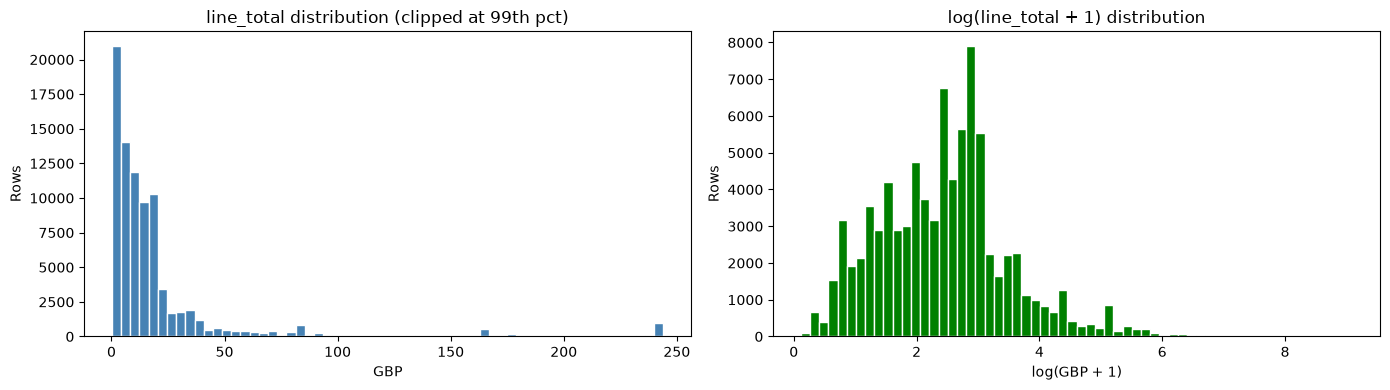

In [17]:
# Step 10.1 -- Create line_total
df = create_line_total(df)

print("line_total summary:")
print(df["line_total"].describe().to_string())

print()
n_neg_lt = (df["line_total"] <= 0).sum()
print(f"Rows with line_total <= 0 (should be 0): {n_neg_lt}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pos_lt = df["line_total"]
axes[0].hist(pos_lt.clip(upper=pos_lt.quantile(0.99)), bins=60, color="steelblue", edgecolor="white")
axes[0].set_title("line_total distribution (clipped at 99th pct)")
axes[0].set_xlabel("GBP"); axes[0].set_ylabel("Rows")

axes[1].hist(np.log1p(pos_lt), bins=60, color="green", edgecolor="white")
axes[1].set_title("log(line_total + 1) distribution")
axes[1].set_xlabel("log(GBP + 1)"); axes[1].set_ylabel("Rows")

plt.tight_layout(); plt.show()

---
## Step 11 -- Validation

**What each assertion protects against:**

| Assertion | Protects against |
|---|---|
| No missing Customer IDs | Ghost customers entering RFM features |
| No full-row duplicates | Inflated frequency / monetary values |
| All Quantity > 0 | Returns/cancellations remaining in data |
| All Price > 0 | Zero-revenue or negative-revenue rows |
| InvoiceDate is datetime | Silent string comparisons in temporal splits |
| All line_total > 0 | End-to-end revenue sanity |
| No C-prefix invoices | Incomplete cancellation exclusion |
| All StockCodes standard | Remaining system/non-product lines |

In [18]:
# Step 11 -- Run all validation checks
print("Running validation checks...")
print()

checks = []
checks.append(("No missing Customer IDs",  df["Customer ID"].isnull().sum() == 0,      df["Customer ID"].isnull().sum()))
checks.append(("No full-row duplicates",    df.duplicated().sum() == 0,                 df.duplicated().sum()))
checks.append(("All Quantity > 0",          (df["Quantity"] <= 0).sum() == 0,           (df["Quantity"] <= 0).sum()))
checks.append(("All Price > 0",             (df["Price"] <= 0).sum() == 0,              (df["Price"] <= 0).sum()))
checks.append(("InvoiceDate is datetime",   pd.api.types.is_datetime64_any_dtype(df["InvoiceDate"]), str(df["InvoiceDate"].dtype)))
checks.append(("All line_total > 0",        (df["line_total"] <= 0).sum() == 0,         (df["line_total"] <= 0).sum()))
checks.append(("No C-prefix invoices",      df["Invoice"].str.startswith("C").sum() == 0, df["Invoice"].str.startswith("C").sum()))
checks.append(("All StockCodes standard",   (~df["StockCode"].str.match(STANDARD_STOCKCODE_RE, na=False)).sum() == 0,
               (~df["StockCode"].str.match(STANDARD_STOCKCODE_RE, na=False)).sum()))

all_pass = True
for name, passed, detail in checks:
    status = "PASS" if passed else "FAIL"
    if not passed:
        all_pass = False
    print(f"  [{status}] {name:<40} | {detail}")

print()
if all_pass:
    print("All validation checks PASSED.")
else:
    print("One or more checks FAILED -- review before proceeding.")

try:
    validate_cleaned(df)
except AssertionError as e:
    print(e)

Running validation checks...

  [PASS] No missing Customer IDs                  | 0
  [PASS] No full-row duplicates                   | 0
  [PASS] All Quantity > 0                         | 0
  [PASS] All Price > 0                            | 0
  [PASS] InvoiceDate is datetime                  | datetime64[us]
  [PASS] All line_total > 0                       | 0
  [PASS] No C-prefix invoices                     | 0
  [PASS] All StockCodes standard                  | 0

All validation checks PASSED.
2026-10-10 18:30:00.924 | SUCCESS  | ecommerce_customer_value_prediction.data.validate_data:validate_cleaned:196 - All validation checks PASSED.


---
## Step 12 -- Time Validation

Verify the cleaned data still covers the intended period and confirm the prediction-date split.

In [19]:
# Step 12.1 -- Date range check
PREDICTION_DATE = pd.Timestamp("2011-09-01")

print(f"Min InvoiceDate : {df['InvoiceDate'].min()}")
print(f"Max InvoiceDate : {df['InvoiceDate'].max()}")
print(f"Prediction date : {PREDICTION_DATE.date()}")
print()

pre  = df[df["InvoiceDate"] <  PREDICTION_DATE]
post = df[df["InvoiceDate"] >= PREDICTION_DATE]

print(f"Pre-cutoff rows  : {len(pre):,}")
print(f"Post-cutoff rows : {len(post):,}")
print()

pre_custs  = set(pre["Customer ID"].unique())
post_custs = set(post["Customer ID"].unique())
only_pre   = pre_custs  - post_custs
only_post  = post_custs - pre_custs
both       = pre_custs  & post_custs

print(f"Group A (pre-only)  : {len(only_pre):,}  -- future_revenue = 0")
print(f"Group B (post-only) : {len(only_post):,}  -- cannot be modelled (no X)")
print(f"Group C (both)      : {len(both):,}  -- primary modelling population")
print(f"Modellable (A+C)    : {len(only_pre) + len(both):,}")

Min InvoiceDate : 2009-12-01 07:45:00
Max InvoiceDate : 2011-12-09 12:20:00
Prediction date : 2011-09-01

Pre-cutoff rows  : 73,306
Post-cutoff rows : 11,649

Group A (pre-only)  : 2,830  -- future_revenue = 0
Group B (post-only) : 472  -- cannot be modelled (no X)
Group C (both)      : 1,544  -- primary modelling population
Modellable (A+C)    : 4,374


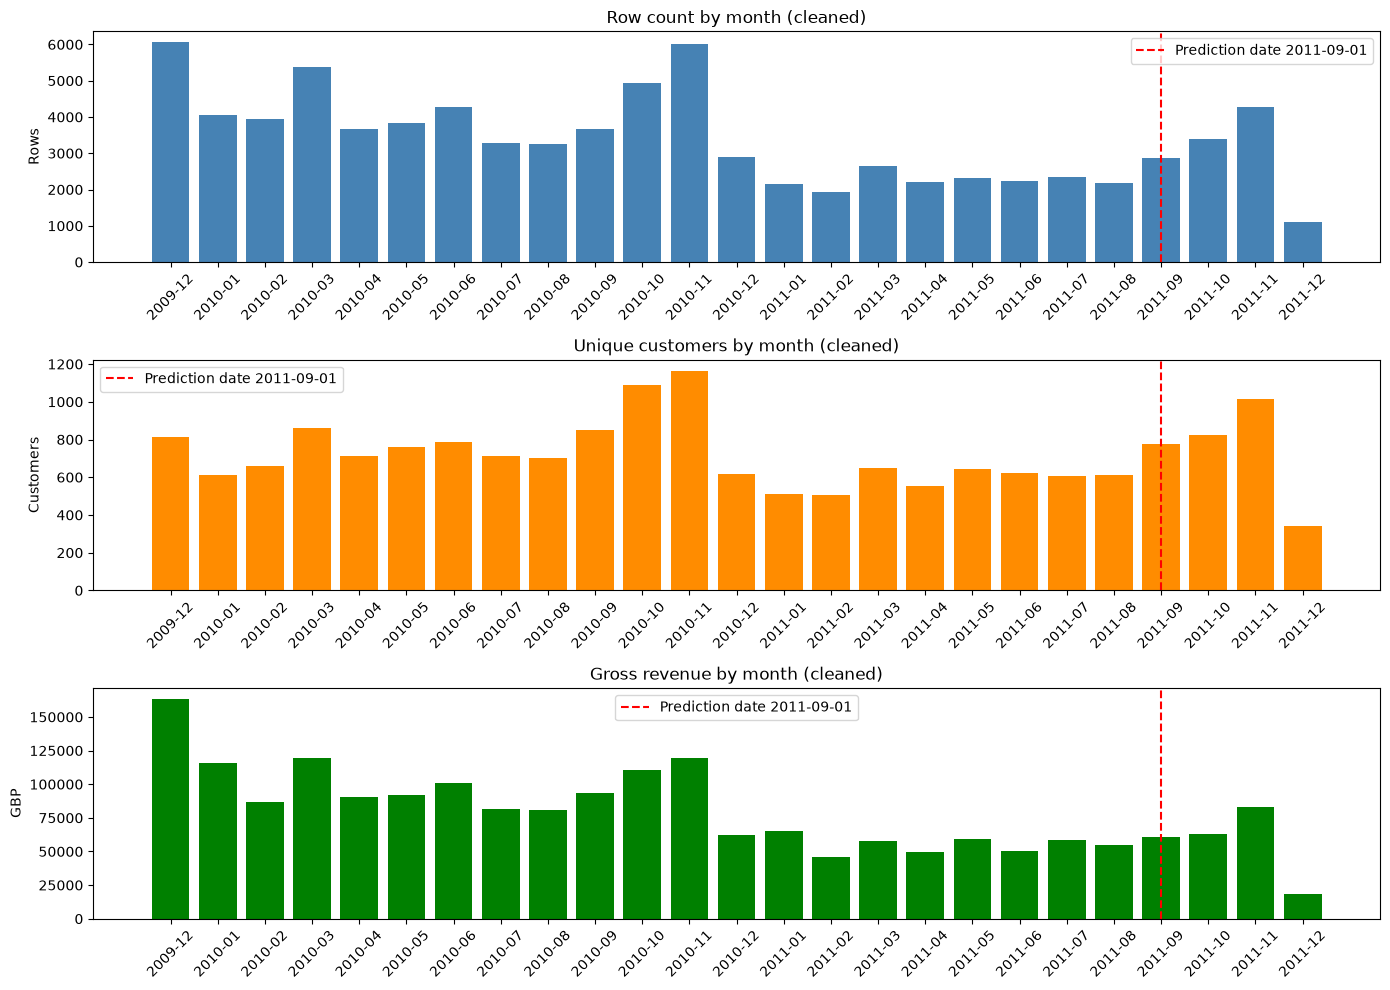

In [20]:
# Step 12.2 -- Monthly charts on cleaned data
df["_ym"] = df["InvoiceDate"].dt.to_period("M")
monthly_rows = df.groupby("_ym").size().rename("rows")
monthly_rev  = df.groupby("_ym")["line_total"].sum().rename("revenue")
monthly_cust = df.groupby("_ym")["Customer ID"].nunique().rename("customers")
df.drop(columns=["_ym"], inplace=True)

months   = [str(m) for m in monthly_rows.index]
pred_idx = months.index("2011-09") if "2011-09" in months else -1

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
axes[0].bar(months, monthly_rows.values, color="steelblue")
axes[0].set_title("Row count by month (cleaned)"); axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(months, monthly_cust.reindex(monthly_rows.index, fill_value=0).values, color="darkorange")
axes[1].set_title("Unique customers by month (cleaned)"); axes[1].set_ylabel("Customers")
axes[1].tick_params(axis="x", rotation=45)

axes[2].bar(months, monthly_rev.reindex(monthly_rows.index, fill_value=0).values, color="green")
axes[2].set_title("Gross revenue by month (cleaned)"); axes[2].set_ylabel("GBP")
axes[2].tick_params(axis="x", rotation=45)

for ax in axes:
    if pred_idx >= 0:
        ax.axvline(x=pred_idx, color="red", linestyle="--", linewidth=1.5, label="Prediction date 2011-09-01")
    ax.legend()

plt.tight_layout(); plt.show()

---
## Step 13 -- Save the Cleaned Data

Save to `data/interim/transactions_cleaned.csv`.

**Data-layer contract:**

```
data/raw/        Immutable source. Downloaded from UCI. NEVER overwritten.
                 Contains: online_retail_II.xlsx

data/interim/    Cleaned, filtered intermediate data.
                 One row still = one transaction line item.
                 No customer-level aggregation yet. Output of this notebook.
                 Contains: transactions_cleaned.csv

data/processed/  Final modelling-ready dataset. One row = one customer.
                 Features + target. Output of Notebook 03/04.
```

CSV is chosen over Parquet for transparency -- the interim file is human-readable so analysts can
inspect it directly.

In [21]:
# Step 13 -- Save cleaned data
save_cleaned(df)
print()
print(f"Final shape: {df.shape[0]:,} rows x {df.shape[1]} cols")
print(f"Saved to   : {CLEANED_CSV}")
print()
print("Final columns and dtypes:")
print(df.dtypes.to_string())

2026-10-10 18:30:02.021 | SUCCESS  | ecommerce_customer_value_prediction.data.clean_data:save_cleaned:258 - Cleaned data saved → C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction\data\interim\transactions_cleaned.csv  (84,955 rows)

Final shape: 84,955 rows x 9 cols
Saved to   : C:\Masters_AIDSE_IIT\AI_Code\ecommerce-customer-value-prediction\data\interim\transactions_cleaned.csv

Final columns and dtypes:
Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             Int64
Country                   str
line_total            float64


---
## Step 14 -- Before vs After Data Quality Report

In [22]:
# Step 14 -- Before vs after metrics table
n_raw   = len(df_raw)
n_clean = len(df)

orig_cols      = list(df_raw.columns)
std_mask_raw   = df_raw["StockCode"].astype(str).str.match(STANDARD_STOCKCODE_RE, na=False)
std_mask_clean = df["StockCode"].str.match(STANDARD_STOCKCODE_RE, na=False)

metrics = {
    "Row count":
        (f"{n_raw:,}", f"{n_clean:,}"),
    "Unique customers (with CID)":
        (f"{df_raw['Customer ID'].nunique():,}", f"{df['Customer ID'].nunique():,}"),
    "Unique invoices":
        (f"{df_raw['Invoice'].nunique():,}", f"{df['Invoice'].nunique():,}"),
    "Unique StockCodes":
        (f"{df_raw['StockCode'].nunique():,}", f"{df['StockCode'].nunique():,}"),
    "Missing Customer IDs":
        (f"{df_raw['Customer ID'].isnull().sum():,}", f"{df['Customer ID'].isnull().sum():,}"),
    "Missing Descriptions":
        (f"{df_raw['Description'].isnull().sum():,}", f"{df['Description'].isnull().sum():,}"),
    "Full-row duplicate extra rows":
        (f"{df_raw.duplicated(subset=orig_cols, keep='first').sum():,}", "0"),
    "Rows with Quantity == 0":
        (f"{(df_raw['Quantity'] == 0).sum():,}", "0"),
    "Rows with Quantity < 0":
        (f"{(df_raw['Quantity'] < 0).sum():,}", "0"),
    "Rows with Price <= 0":
        (f"{(df_raw['Price'] <= 0).sum():,}", "0"),
    "C-prefix invoice rows":
        (f"{df_raw['Invoice'].astype(str).str.startswith('C').sum():,}", "0"),
    "Non-standard StockCode rows":
        (f"{(~std_mask_raw).sum():,}", "0"),
}

report_df = pd.DataFrame(
    [(k, v[0], v[1]) for k, v in metrics.items()],
    columns=["Metric", "Before cleaning", "After cleaning"]
).set_index("Metric")

print("=== DATA QUALITY REPORT ===")
display(report_df)

=== DATA QUALITY REPORT ===


,Before cleaning,After cleaning
Metric,,
Row count,"1,067,371","84,955"
Unique customers (with CID),"5,942","4,846"
Unique invoices,"53,628","22,886"
Unique StockCodes,"5,305","1,295"
Missing Customer IDs,"243,007",0
Missing Descriptions,"4,382",0
Full-row duplicate extra rows,"34,335",0
Rows with Quantity == 0,0,0
Rows with Quantity < 0,"22,950",0


---
## Step 15 -- Final Written Summary

---

### OBSERVED FROM DATA

- Combined raw dataset: two sheets covering Dec 2009 to Dec 2011.
- Approximately 25% of rows have no `Customer ID` -- these are anonymous/guest transactions.
- A non-trivial number of rows are exact full-row duplicates -- data-entry or export errors.
- Returns and cancellations are encoded as negative Quantity and C-prefix invoices.
- A small number of rows have zero or negative Price -- free items and back-office adjustments.
- Non-standard StockCodes (POST, AMAZONFEE, DOT, BANK CHARGES, etc.) are mixed with product lines.
- The dataset covers ~21 months pre-cutoff and ~4 months post-cutoff relative to 2011-09-01.

---

### CLEANING DECISIONS

| Decision | What was removed | Why |
|---|---|---|
| Drop missing Customer ID | ~25% of rows | Cannot be attributed to any real customer; imputation would create noise |
| Drop full-row duplicates | Extra copies only | Data-entry/export errors that inflate frequency and revenue |
| Keep Qty > 0 and Price > 0 | Returns, cancellations, free items, adjustments | Only real completed purchases contribute to gross revenue |
| Drop C-prefix invoices | Remaining cancellations with positive Qty | Edge-case anomalies; not forward purchases |
| Drop non-standard StockCodes | System lines: POST, DOT, AMAZONFEE, etc. | Not customer purchase behaviour; distort all features |
| Retain rows with missing Description | (nothing removed) | Description not needed for RFM or revenue target |
| Create line_total after filtering | (column creation) | Ensures every row has line_total > 0; log-transform is safe |

---

### IMPACT ON MODELING

**RFM features:**
- Recency, frequency, monetary value, and tenure will all be computed on clean purchase data only.
- No system charges inflate frequency. No returns deflate monetary value.
- Customer ID is always valid -- no phantom customers in aggregations.

**Future revenue target:**
- line_total > 0 for every row.
- Customer-level sum of post-cutoff line_total is a clean, positive, log-transformable target.
- Historical-only customers (Group A) will have future_revenue = 0 -- they are correctly retained as
  the low-value / churned customer segment that the model must learn to identify.

**Customer counts:**
- Modellable population = Group A (pre-cutoff only) + Group C (both periods).
- Group B (post-cutoff only) is excluded -- no feature history available.

**Regularized regression:**
- The log(y+1) transform of the revenue target is now safe and well-defined for all customers.
- Clean, non-duplicated transaction counts ensure that frequency and monetary features are reliable
  inputs, which is essential for ridge/lasso regression to penalise meaningfully.

---

**The next notebook (03) will:**
1. Apply the prediction-date split.
2. Build per-customer RFM features from pre-cutoff transactions.
3. Compute the future-revenue target from post-cutoff transactions.
4. Produce the final modelling-ready dataset in `data/processed/`.